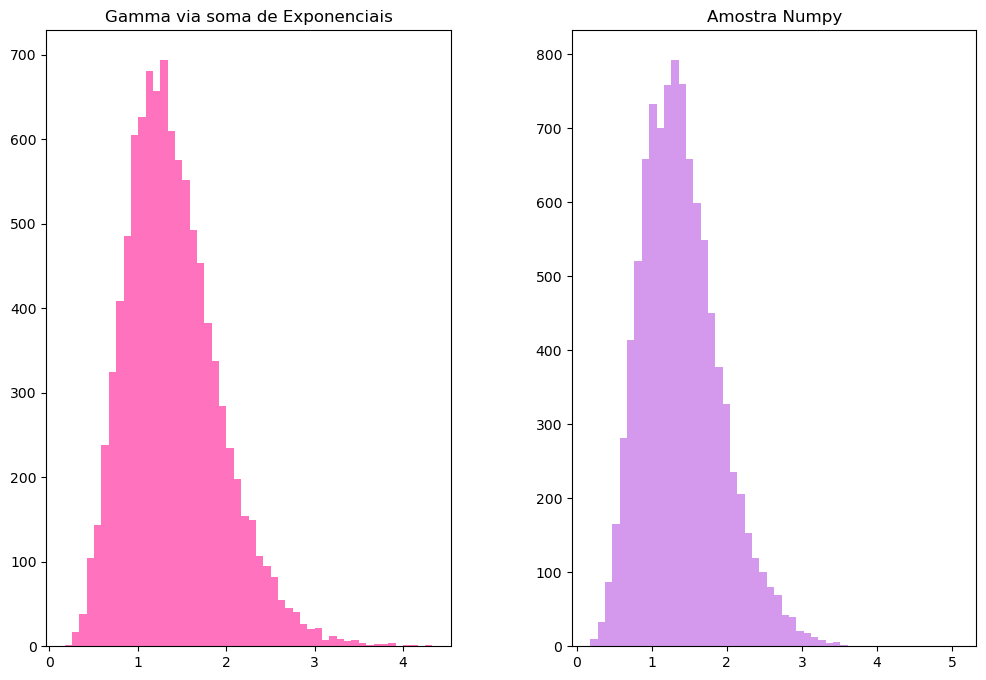

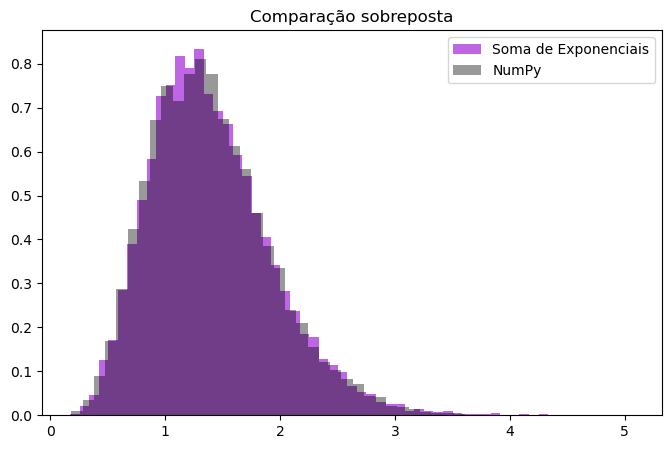

In [16]:
#Exercicio 1

import numpy as np
import math

n = 10000
k = 7
lamb = 5

#gerando gamma via soma de exponenciais
amostra = []

for i in range(n):
    soma = 0
    for j in range(k):
        u = np.random.uniform(0, 1)
        exponencial = -math.log(u) / lamb
        soma += exponencial
    amostra.append(soma)

#gerando a gamma via numpy
gamma_numpy = np.random.gamma(shape=k, scale=1/lamb, size=n)

#gerando o histograma

import matplotlib.pyplot as plt

fig, eixo = plt.subplots(1,2, figsize=(12,8))
plt.subplots_adjust(hspace=0.5, wspace=0.3)

eixo[0].hist(amostra, bins=50, alpha=0.6, color='deeppink')
eixo[0].set_title("Gamma via soma de Exponenciais")

eixo[1].hist(gamma_numpy, bins=50, alpha=0.4, color='darkviolet')
eixo[1].set_title("Amostra Numpy")

plt.show()

#histograma com sobreposição pra comparar melhor
plt.figure(figsize=(8,5))
plt.hist(amostra, bins=50, density=True, alpha=0.6, color='darkviolet', label='Soma de Exponenciais')
plt.hist(gamma_numpy, bins=50, density=True, alpha=0.4, color='black', label='NumPy')
plt.title(f"Comparação sobreposta")
plt.legend()
plt.show()

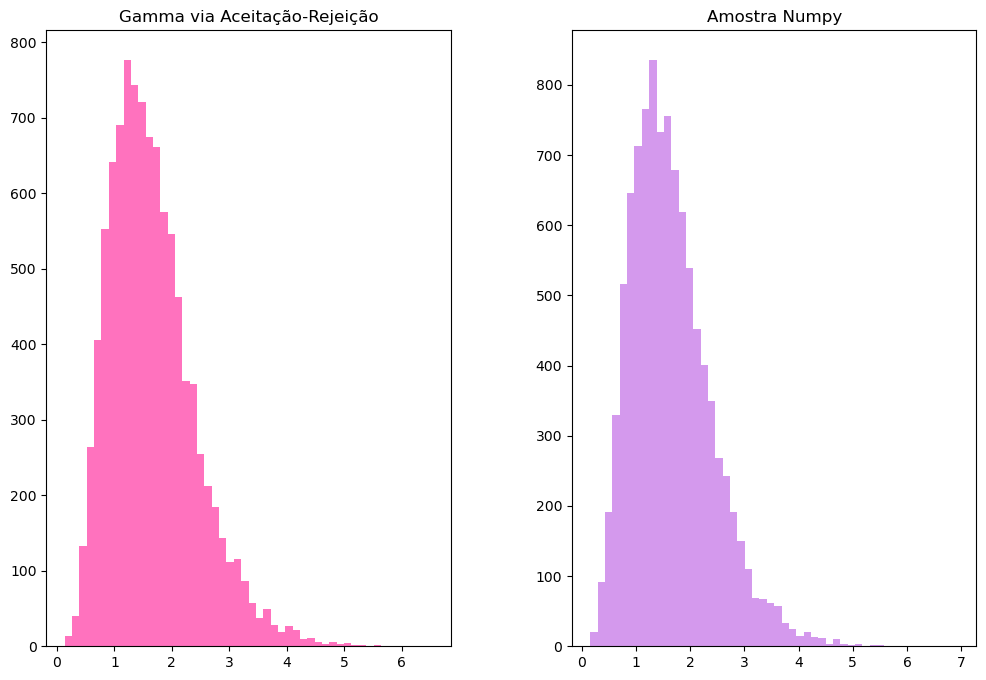

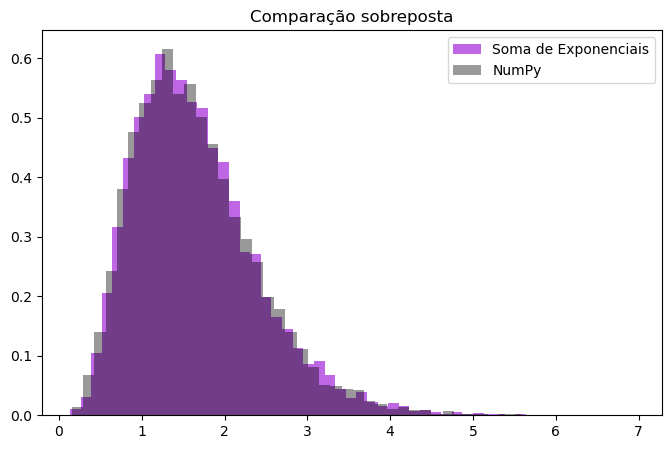

In [17]:
#Exercicio 2

n = 10000
alpha = 5  
lamb = 3

# proposta de parametros para a exponencial e calculando a constante c
mu = lamb / alpha
c = (lamb**alpha / (math.gamma(alpha) * mu)) * (((alpha - 1) / (lamb - mu))**(alpha - 1)) * math.exp(-(alpha - 1))

# gerando gamma via aceitação-rejeição
def densidade_gamma(x):
    if x <= 0: return 0
    return (lamb**alpha / math.gamma(alpha)) * (x**(alpha - 1)) * math.exp(-lamb * x)

# densidade da exponencial
def g_exponencial(x):
    if x <= 0: return 0
    return mu * math.exp(-mu * x)

amostra = []

while len(amostra) < n:
    u1 = np.random.uniform(0, 1)
    y = -math.log(u1) / mu
    u2 = np.random.uniform(0, 1)
    
    if u2 <= densidade_gamma(y) / (c * g_exponencial(y)):
        amostra.append(y)

#gerando gamma via numpy
gamma_numpy = np.random.gamma(shape=alpha, scale=1/lamb, size=n)

#gerando o histograma
fig, eixo = plt.subplots(1,2, figsize=(12,8))
plt.subplots_adjust(hspace=0.5, wspace=0.3)

eixo[0].hist(amostra, bins=50, alpha=0.6, color='deeppink')
eixo[0].set_title("Gamma via Aceitação-Rejeição")

eixo[1].hist(gamma_numpy, bins=50, alpha=0.4, color='darkviolet')
eixo[1].set_title("Amostra Numpy")

plt.show()

#histograma com sobreposição pra comparar melhor
plt.figure(figsize=(8,5))
plt.hist(amostra, bins=50, density=True, alpha=0.6, color='darkviolet', label='Soma de Exponenciais')
plt.hist(gamma_numpy, bins=50, density=True, alpha=0.4, color='black', label='NumPy')
plt.title(f"Comparação sobreposta")
plt.legend()
plt.show()

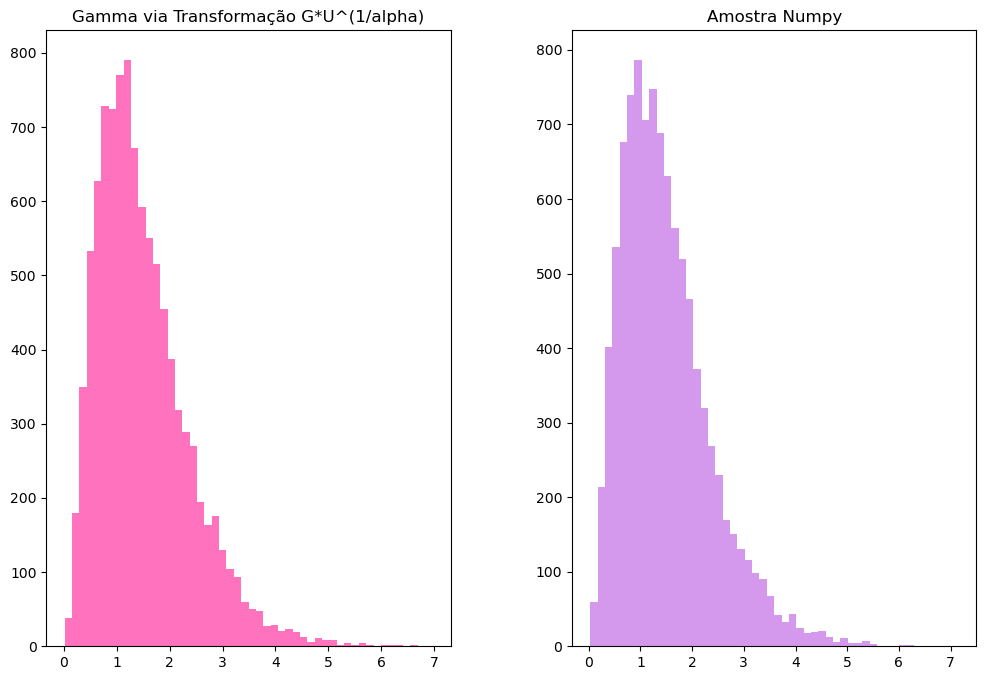

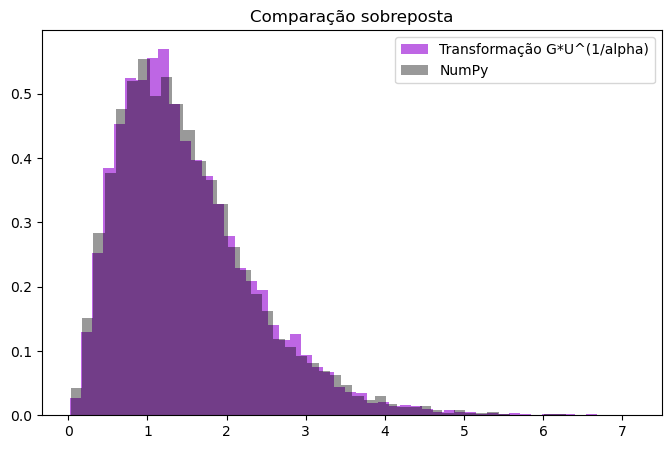

In [18]:
#Exercicio 3

n = 10000
alpha = 3
lamb = 2
alpha1 = alpha + 1  

# gerando gamma via G*U^(1/alpha)
amostra = []

for i in range(n):
    G = 0
    for j in range(int(alpha1)):
        u_exp = np.random.uniform(0, 1)
        G += -math.log(u_exp) / lamb
        
    U = np.random.uniform(0, 1)
    X = G * (U ** (1 / alpha))
    amostra.append(X)

# gerando gamma via numpy
gamma_numpy = np.random.gamma(shape=alpha, scale=1/lamb, size=n)

#gerando o histograma
fig, eixo = plt.subplots(1,2, figsize=(12,8))
plt.subplots_adjust(hspace=0.5, wspace=0.3)

eixo[0].hist(amostra, bins=50, alpha=0.6, color='deeppink')
eixo[0].set_title("Gamma via Transformação G*U^(1/alpha)")

eixo[1].hist(gamma_numpy, bins=50, alpha=0.4, color='darkviolet')
eixo[1].set_title("Amostra Numpy")

plt.show()

#histograma com sobreposição pra comparar melhor
plt.figure(figsize=(8,5))
plt.hist(amostra, bins=50, density=True, alpha=0.6, color='darkviolet', label='Transformação G*U^(1/alpha)')
plt.hist(gamma_numpy, bins=50, density=True, alpha=0.4, color='black', label='NumPy')
plt.title(f"Comparação sobreposta")
plt.legend()
plt.show()



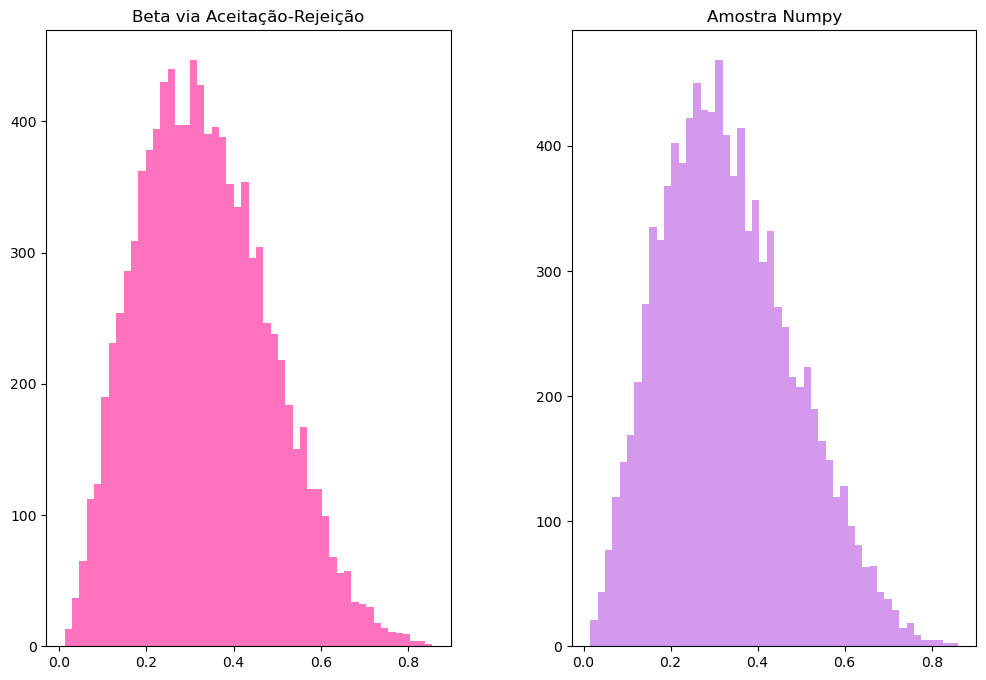

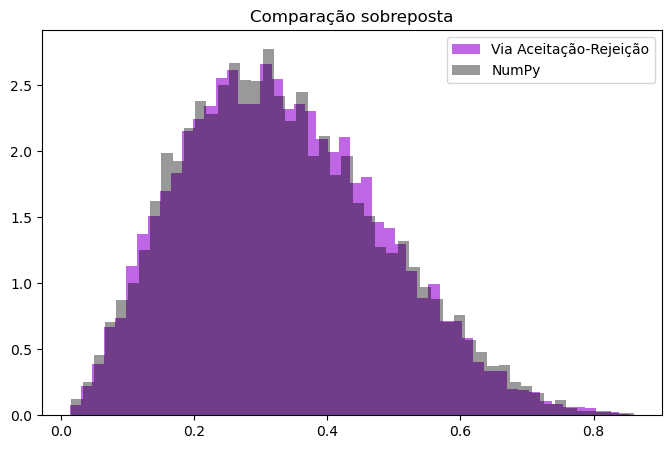

In [19]:
#Exercicio 4

n = 10000
alpha = 3
beta = 6

# obtendo a constante de normalização
constante_b = (math.gamma(alpha) * math.gamma(beta)) / math.gamma(alpha + beta)

# densidade da beta utilizando a constante
def densidade_beta(x):
    if 0 <= x <= 1:
        return (1 / constante_b) * (x**(alpha - 1)) * ((1 - x)**(beta - 1))
    return 0

# obtendo o c a partir da moda
moda = (alpha - 1) / (alpha + beta - 2)
c = densidade_beta(moda)

# gerando beta via aceitação-rejeçao
amostra = []

while len(amostra) < n:
    y = np.random.uniform(0, 1)
    u = np.random.uniform(0, 1)
    
    if u <= densidade_beta(y) / c:
        amostra.append(y)

# gerando beta via numpy
beta_numpy = np.random.beta(alpha, beta, n)

#gerando o histograma
fig, eixo = plt.subplots(1,2, figsize=(12,8))
plt.subplots_adjust(hspace=0.5, wspace=0.3)

eixo[0].hist(amostra, bins=50, alpha=0.6, color='deeppink')
eixo[0].set_title("Beta via Aceitação-Rejeição")

eixo[1].hist(beta_numpy, bins=50, alpha=0.4, color='darkviolet')
eixo[1].set_title("Amostra Numpy")

plt.show()

#histograma com sobreposição pra comparar melhor
plt.figure(figsize=(8,5))
plt.hist(amostra, bins=50, density=True, alpha=0.6, color='darkviolet', label='Via Aceitação-Rejeição')
plt.hist(beta_numpy, bins=50, density=True, alpha=0.4, color='black', label='NumPy')
plt.title(f"Comparação sobreposta")
plt.legend()
plt.show()

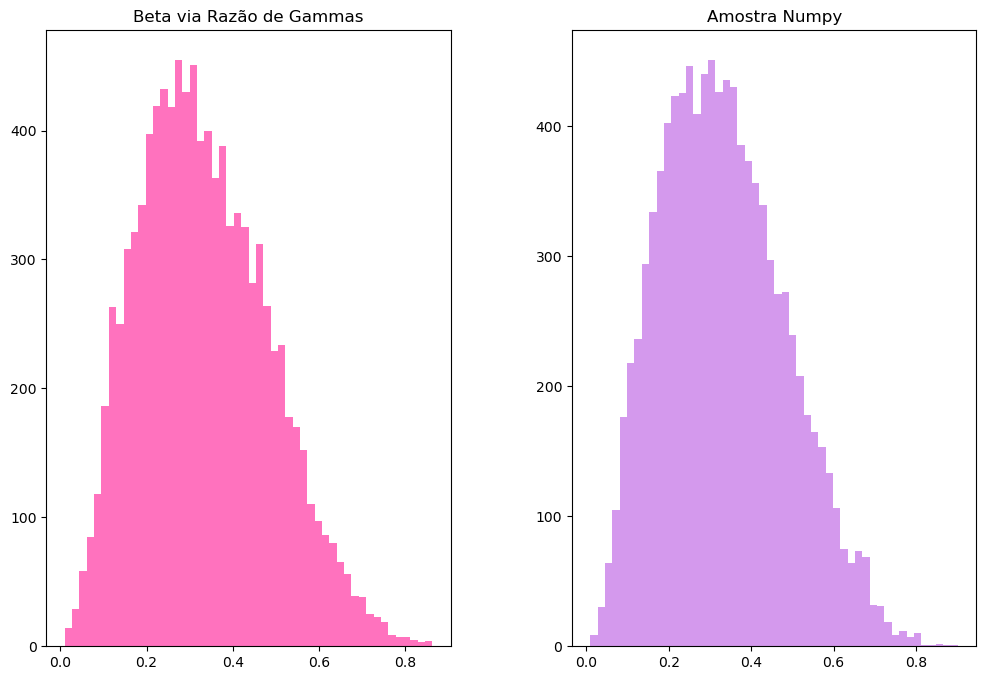

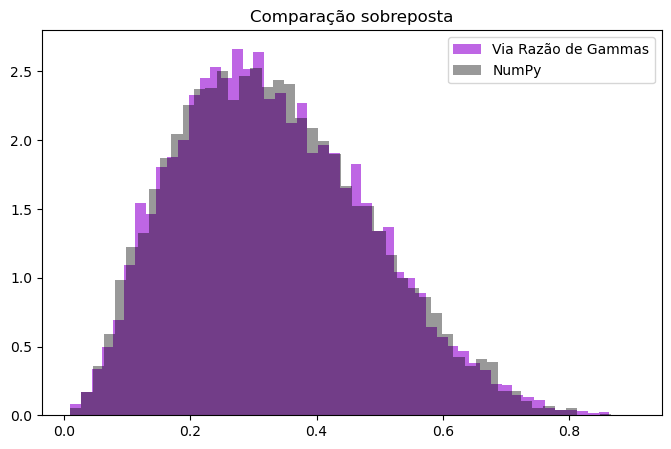

In [20]:
#Exercicio 5

n = 10000
alpha = 3
beta = 6

#gerando beta via razão de gammas
amostra = []

for i in range(n):
    G1 = 0
    for j in range(alpha):
        u = np.random.uniform(0, 1)
        G1 += -math.log(u) 
        
    
    G2 = 0
    for j in range(beta):
        u = np.random.uniform(0, 1)
        G2 += -math.log(u)
        
    
    X = G1 / (G1 + G2)
    amostra.append(X)

# gerando beta via numpy
beta_numpy = np.random.beta(alpha, beta, n)

#gerando o histograma
fig, eixo = plt.subplots(1,2, figsize=(12,8))
plt.subplots_adjust(hspace=0.5, wspace=0.3)

eixo[0].hist(amostra, bins=50, alpha=0.6, color='deeppink')
eixo[0].set_title("Beta via Razão de Gammas")

eixo[1].hist(beta_numpy, bins=50, alpha=0.4, color='darkviolet')
eixo[1].set_title("Amostra Numpy")

plt.show()

#histograma com sobreposição pra comparar melhor
plt.figure(figsize=(8,5))
plt.hist(amostra, bins=50, density=True, alpha=0.6, color='darkviolet', label='Via Razão de Gammas')
plt.hist(beta_numpy, bins=50, density=True, alpha=0.4, color='black', label='NumPy')
plt.title(f"Comparação sobreposta")
plt.legend()
plt.show()